<a href="https://colab.research.google.com/github/Goutham-kc/AIML/blob/main/Stacking.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Dataset Shape: (100000, 9)
   gender   age  hypertension  heart_disease smoking_history    bmi  \
0  Female  80.0             0              1           never  25.19   
1  Female  54.0             0              0         No Info  27.32   
2    Male  28.0             0              0           never  27.32   
3  Female  36.0             0              0         current  23.45   
4    Male  76.0             1              1         current  20.14   

   HbA1c_level  blood_glucose_level  diabetes  
0          6.6                  140         0  
1          6.6                   80         0  
2          5.7                  158         0  
3          5.0                  155         0  
4          4.8                  155         0  

Random Forest completed.

Random Forest → SVM Accuracy: 0.96785

Classification Report:
              precision    recall  f1-score   support

 No Diabetes       0.97      0.99      0.98     18300
    Diabetes       0.90      0.70      0.79      1700

    a

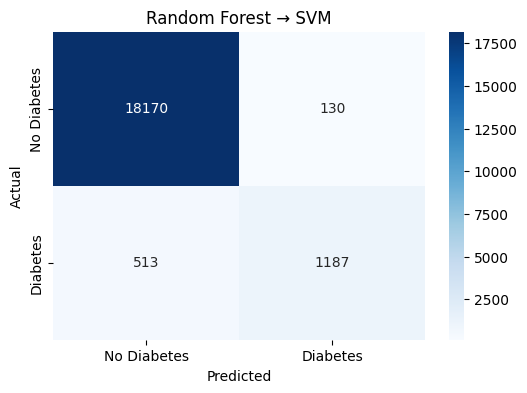

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

# 1. Load dataset
df = pd.read_csv("diabetes_prediction_dataset.csv")

print("Dataset Shape:", df.shape)
print(df.head())

# 2. Separate features and target
X = df.drop("diabetes", axis=1)
y = df["diabetes"]

# 3. Convert categorical variables to numerical
X = pd.get_dummies(X, drop_first=True)

# 4. Split dataset
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# ==========================================
# STAGE 1: RANDOM FOREST
# ==========================================

rf = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

# Train Random Forest
rf.fit(X_train, y_train)

# Get Random Forest probabilities
rf_train_prob = rf.predict_proba(X_train)[:, 1]
rf_test_prob = rf.predict_proba(X_test)[:, 1]

print("\nRandom Forest completed.")

# ==========================================
# STAGE 2: PREPARE DATA FOR SVM
# ==========================================

# Add Random Forest probability as a new feature
X_train_svm = X_train.copy()
X_test_svm = X_test.copy()

X_train_svm["rf_probability"] = rf_train_prob
X_test_svm["rf_probability"] = rf_test_prob

# ==========================================
# SCALE DATA FOR SVM
# ==========================================

scaler = StandardScaler()

X_train_svm = scaler.fit_transform(X_train_svm)
X_test_svm = scaler.transform(X_test_svm)

# ==========================================
# STAGE 3: SVM
# ==========================================

svm = SVC(
    kernel="rbf",
    probability=True,
    random_state=42
)

# Train SVM using original features + RF result
svm.fit(X_train_svm, y_train)

# ==========================================
# FINAL PREDICTION
# ==========================================

y_pred = svm.predict(X_test_svm)

# ==========================================
# EVALUATION
# ==========================================

accuracy = accuracy_score(y_test, y_pred)

print("\nRandom Forest → SVM Accuracy:", accuracy)

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred,
    target_names=["No Diabetes", "Diabetes"]
))

# Confusion Matrix
cm = confusion_matrix(y_test, y_pred)

print("\nConfusion Matrix:")
print(cm)

# Plot confusion matrix
plt.figure(figsize=(6, 4))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["No Diabetes", "Diabetes"],
    yticklabels=["No Diabetes", "Diabetes"]
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Random Forest → SVM")
plt.show()